# BnSentMix — Model 1 Final Unseen-Test Evaluation

This notebook loads the **already fitted** word + character TF-IDF Linear SVM and evaluates it once on the locked unseen test split. It performs **no training, model selection, threshold tuning, or hyperparameter tuning**.

Run the cells from top to bottom in a new Kaggle notebook after adding the saved output of `olidopu/final-model1` as an input.

In [1]:
# Cell 1 — Imports and frozen protocol constants
from pathlib import Path
import hashlib
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_recall_fscore_support
)

EXPECTED_RAW_SHA256 = '148f23eb3dc40c1012a973efec920eaccc39700a74e5bcfb56806b0bf389029d'
EXPECTED_SPLIT_SHA256 = '7be81e52030967319d43ddc1e1feaf9817f9c3011a9b914265c34b5ce0ab8ec5'
EXPECTED_TEST_ROWS = 2973
LABELS = [0, 1, 2, 3]
LABEL_NAMES = {0: 'positive', 1: 'negative', 2: 'neutral', 3: 'mixed'}
MIXED_LABEL = 3

OUTPUT_DIR = Path('/kaggle/working/bnsentmix_model1_final_test')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('scikit-learn:', sklearn.__version__)
print('Output directory:', OUTPUT_DIR)

scikit-learn: 1.6.1
Output directory: /kaggle/working/bnsentmix_model1_final_test


In [2]:
# Cell 2 — Locate the saved artifacts and verify their checksums
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def find_one(filename):
    matches = list(Path('/kaggle/input').rglob(filename))
    if len(matches) != 1:
        raise FileNotFoundError(
            f'Expected exactly one {filename!r} under /kaggle/input, found {len(matches)}: {matches}'
        )
    return matches[0]

DATA_PATH = Path('/kaggle/input/datasets/olidopu/bnsentmix/dataset.csv')
SPLIT_PATH = find_one('bnsentmix_locked_split.csv')
MANIFEST_PATH = find_one('split_manifest.json')
MODEL_PATH = find_one('model1_tfidf_linear_svm.joblib')

assert DATA_PATH.exists(), f'Dataset not found: {DATA_PATH}'
raw_sha = sha256_file(DATA_PATH)
split_sha = sha256_file(SPLIT_PATH)
assert raw_sha == EXPECTED_RAW_SHA256, f'Raw dataset checksum mismatch: {raw_sha}'
assert split_sha == EXPECTED_SPLIT_SHA256, f'Locked split checksum mismatch: {split_sha}'

with open(MANIFEST_PATH, encoding='utf-8') as handle:
    manifest = json.load(handle)
assert manifest['raw_sha256'] == EXPECTED_RAW_SHA256
assert manifest['split_sha256'] == EXPECTED_SPLIT_SHA256

print('Dataset verified:', DATA_PATH)
print('Locked split verified:', SPLIT_PATH)
print('Saved Model 1 found:', MODEL_PATH)
print('Split SHA-256:', split_sha)

Dataset verified: /kaggle/input/datasets/olidopu/bnsentmix/dataset.csv
Locked split verified: /kaggle/input/notebooks/olidopu/final-model1/bnsentmix_protocol_2026/bnsentmix_locked_split.csv
Saved Model 1 found: /kaggle/input/notebooks/olidopu/final-model1/bnsentmix_model1/model1_tfidf_linear_svm.joblib
Split SHA-256: 7be81e52030967319d43ddc1e1feaf9817f9c3011a9b914265c34b5ce0ab8ec5


In [3]:
# Cell 3 — Load only the sealed test partition
split_df = pd.read_csv(SPLIT_PATH)
required_columns = {'source_row_id', 'group_id', 'text', 'label', 'split'}
assert required_columns.issubset(split_df.columns), (
    f'Missing split columns: {required_columns - set(split_df.columns)}'
)
assert split_df.groupby('group_id')['split'].nunique().max() == 1, 'Group leakage detected.'

test_df = split_df.loc[split_df['split'].eq('test')].copy().reset_index(drop=True)
test_df['label'] = test_df['label'].astype(int)
assert len(test_df) == EXPECTED_TEST_ROWS, f'Expected {EXPECTED_TEST_ROWS} test rows, got {len(test_df)}'
assert sorted(test_df['label'].unique().tolist()) == LABELS

test_distribution = (
    test_df['label'].value_counts().sort_index()
    .rename(index=LABEL_NAMES).rename('support').to_frame()
)
display(test_distribution)
print('Sealed unseen-test rows:', len(test_df))

,support
label,
positive,768
negative,922
neutral,1030
mixed,253


Sealed unseen-test rows: 2973


In [4]:
# Cell 4 — Load the frozen fitted feature extractor and classifier
artifact = joblib.load(MODEL_PATH)
required_keys = {'features', 'classifier', 'selected_C', 'label_names', 'raw_sha256', 'split_sha256'}
assert required_keys.issubset(artifact), f'Missing artifact keys: {required_keys - set(artifact)}'
assert artifact['raw_sha256'] == EXPECTED_RAW_SHA256
assert artifact['split_sha256'] == EXPECTED_SPLIT_SHA256
assert float(artifact['selected_C']) == 0.5, 'Unexpected selected C.'

features = artifact['features']
classifier = artifact['classifier']

print('Frozen classifier:', classifier)
print('Selected validation C:', artifact['selected_C'])
print('No fitting or tuning will be performed.')

Frozen classifier: LinearSVC(C=0.5, max_iter=10000, random_state=2026)
Selected validation C: 0.5
No fitting or tuning will be performed.


In [5]:
# Cell 5 — One-time unseen-test prediction
X_test = features.transform(test_df['text'].astype(str))
y_true = test_df['label'].to_numpy()
y_pred = classifier.predict(X_test).astype(int)

assert len(y_pred) == len(test_df)
assert set(np.unique(y_pred)).issubset(set(LABELS))
print('Prediction complete:', len(y_pred), 'unseen examples')

Prediction complete: 2973 unseen examples


In [6]:
# Cell 6 — Final metrics and per-class report
mixed_precision, mixed_recall, mixed_f1, mixed_support = precision_recall_fscore_support(
    y_true, y_pred, labels=[MIXED_LABEL], average=None, zero_division=0
)

metrics = {
    'model': 'M1 Word+Char TF-IDF Linear SVM',
    'split': 'locked_final_test',
    'n_test': int(len(y_true)),
    'accuracy': float(accuracy_score(y_true, y_pred)),
    'macro_f1': float(f1_score(y_true, y_pred, labels=LABELS, average='macro')),
    'weighted_f1': float(f1_score(y_true, y_pred, labels=LABELS, average='weighted')),
    'mixed_precision': float(mixed_precision[0]),
    'mixed_recall': float(mixed_recall[0]),
    'mixed_f1': float(mixed_f1[0]),
    'mixed_support': int(mixed_support[0]),
    'selected_C': float(artifact['selected_C']),
    'split_sha256': EXPECTED_SPLIT_SHA256,
}

summary = pd.DataFrame([metrics])
display(summary[['accuracy', 'macro_f1', 'weighted_f1', 'mixed_precision', 'mixed_recall', 'mixed_f1']].round(4))

report = classification_report(
    y_true, y_pred, labels=LABELS,
    target_names=[LABEL_NAMES[label] for label in LABELS],
    output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report).T
display(report_df.round(4))

,accuracy,macro_f1,weighted_f1,mixed_precision,mixed_recall,mixed_f1
0,0.7403,0.7118,0.7383,0.7079,0.498,0.5847


,precision,recall,f1-score,support
positive,0.7810,0.7617,0.7713,768.0000
negative,0.7170,0.7885,0.7510,922.0000
neutral,0.7393,0.7408,0.7401,1030.0000
mixed,0.7079,0.4980,0.5847,253.0000
accuracy,0.7403,0.7403,0.7403,0.7403
macro avg,0.7363,0.6973,0.7118,2973.0000
weighted avg,0.7405,0.7403,0.7383,2973.0000


,pred_positive,pred_negative,pred_neutral,pred_mixed
true_positive,585,64,102,17
true_negative,47,727,131,17
true_neutral,83,166,763,18
true_mixed,34,57,36,126


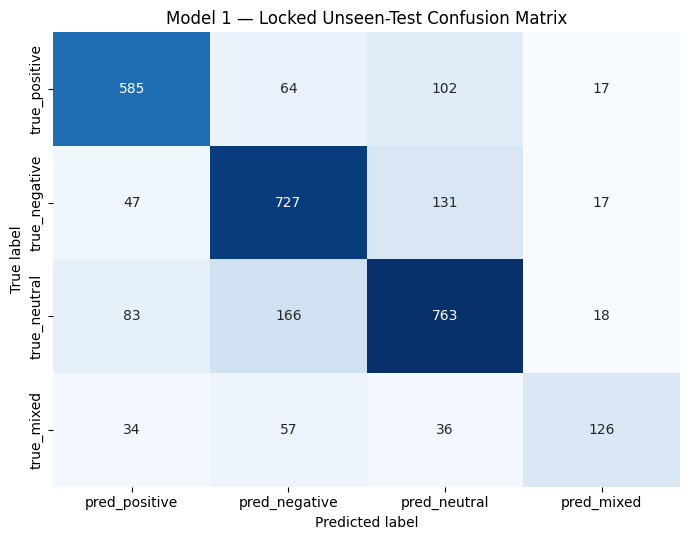

In [7]:
# Cell 7 — Confusion matrix
class_names = [LABEL_NAMES[label] for label in LABELS]
cm = confusion_matrix(y_true, y_pred, labels=LABELS)
cm_df = pd.DataFrame(
    cm,
    index=[f'true_{name}' for name in class_names],
    columns=[f'pred_{name}' for name in class_names],
)
display(cm_df)

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Model 1 — Locked Unseen-Test Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'FINAL_confusion_matrix.png', dpi=200, bbox_inches='tight')
plt.show()

In [8]:
# Cell 8 — Save all paper-ready Model 1 final-test artifacts
prediction_df = test_df[['source_row_id', 'group_id', 'text', 'label']].copy()
prediction_df['label_name'] = prediction_df['label'].map(LABEL_NAMES)
prediction_df['prediction'] = y_pred
prediction_df['prediction_name'] = prediction_df['prediction'].map(LABEL_NAMES)
prediction_df['correct'] = prediction_df['label'].eq(prediction_df['prediction'])

prediction_df.to_csv(OUTPUT_DIR / 'FINAL_test_predictions.csv', index=False)
summary.to_csv(OUTPUT_DIR / 'FINAL_test_summary.csv', index=False)
report_df.to_csv(OUTPUT_DIR / 'FINAL_classification_report.csv')
cm_df.to_csv(OUTPUT_DIR / 'FINAL_confusion_matrix.csv')
with open(OUTPUT_DIR / 'FINAL_test_metrics.json', 'w', encoding='utf-8') as handle:
    json.dump(metrics, handle, indent=2, ensure_ascii=False)

print('FINAL MODEL 1 RESULT')
print(json.dumps({k: v for k, v in metrics.items() if k not in {'split_sha256'}}, indent=2))
print('\nSaved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(' -', path.name)
print('\nDo not tune Model 1 after viewing this result.')

FINAL MODEL 1 RESULT
{
  "model": "M1 Word+Char TF-IDF Linear SVM",
  "split": "locked_final_test",
  "n_test": 2973,
  "accuracy": 0.7403296333669694,
  "macro_f1": 0.7117592731653778,
  "weighted_f1": 0.738299743125022,
  "mixed_precision": 0.7078651685393258,
  "mixed_recall": 0.4980237154150198,
  "mixed_f1": 0.5846867749419954,
  "mixed_support": 253,
  "selected_C": 0.5
}

Saved files:
 - FINAL_classification_report.csv
 - FINAL_confusion_matrix.csv
 - FINAL_confusion_matrix.png
 - FINAL_test_metrics.json
 - FINAL_test_predictions.csv
 - FINAL_test_summary.csv

Do not tune Model 1 after viewing this result.


## What to keep after the run

Save the Kaggle version and retain the complete `bnsentmix_model1_final_test` output folder. In particular, keep `FINAL_test_predictions.csv`; it will later be used for paired statistical comparison across Models 1–6.